In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

file_path = "../data/rpw_dataset_2011_2025_q1.xlsx"

# Check the available worksheets
excel_file = pd.ExcelFile(file_path)
print(excel_file.sheet_names)

Matplotlib is building the font cache; this may take a moment.


['Terms of Use', 'Methodology', 'Legend', 'Countries', 'Dataset (up to Q1 2016)', 'Dataset (from Q2 2016)']


In [2]:
df = pd.read_excel(
    file_path,
    sheet_name=excel_file.sheet_names[-1]
)

print("Dataset shape:", df.shape)
print(df.columns.tolist())
df.head()

Dataset shape: (197999, 42)
['id', 'period', 'source_code', 'source_name', 'source_region', 'source_income', 'source_lending', 'source_G8G20', 'destination_code', 'destination_name', 'destination_region', 'destination_income', 'destination_lending', 'destination_G8G20', 'firm', 'firm_type', 'payment instrument', 'access point', 'speed actual', 'cc1 lcu amount', 'cc1 denomination amount', 'cc1 lcu code', 'cc1 lcu fee', 'cc1 lcu fx rate', 'cc1 fx margin', 'cc1 total cost %', 'cc2 lcu amount', 'cc2 denomination amount', 'cc2 lcu code', 'cc2 lcu fee', 'cc2 lcu fx rate', 'cc2 fx margin', 'cc2 total cost %', 'inter lcu bank fx', 'transparent', 'Standard Note', 'note2', 'receiving network coverage', 'pickup location', 'pickup method', 'date', 'corridor']


,id,period,source_code,source_name,source_region,source_income,source_lending,source_G8G20,destination_code,destination_name,...,cc2 total cost %,inter lcu bank fx,transparent,Standard Note,note2,receiving network coverage,pickup location,pickup method,date,corridor
0,620160001,2016_2Q,AGO,Angola,Sub-Saharan Africa,Lower middle income,IBRD,..,NAM,Namibia,...,14.36,0.0908,yes,NaN,NaN,High,Agent,Cash,11/May/2016,AGONAM
1,620160002,2016_2Q,AGO,Angola,Sub-Saharan Africa,Lower middle income,IBRD,..,NAM,Namibia,...,11.78,0.0908,yes,NaN,NaN,High,Agent,Cash,11/May/2016,AGONAM
2,620160003,2016_2Q,AGO,Angola,Sub-Saharan Africa,Lower middle income,IBRD,..,NAM,Namibia,...,10.93,1.0000,no,This RSP is not transparent: the exchange rate...,NaN,Low,NaN,Bank account,11/May/2016,AGONAM
3,620160004,2016_2Q,ARE,United Arab Emirates,..,High income,..,..,BGD,Bangladesh,...,1.17,21.3380,yes,NaN,NaN,High,Agent,Cash,09/May/2016,AREBGD
4,620160005,2016_2Q,ARE,United Arab Emirates,..,High income,..,..,BGD,Bangladesh,...,0.95,21.3380,yes,NaN,NaN,High,Agent,Cash,09/May/2016,AREBGD


In [3]:
# Filter transfers originating from the United Kingdom
uk_df = df[df["source_code"] == "GBR"].copy()

print("Total UK outbound observations:", len(uk_df))

print("\nNumber of destination countries:")
print(uk_df["destination_name"].nunique())

print("\nDestination countries:")
print(uk_df["destination_name"].value_counts())

Total UK outbound observations: 23066

Number of destination countries:
33

Destination countries:
destination_name
Philippines     1444
India           1193
Bangladesh      1057
Ghana           1008
Kenya            945
Poland           924
Pakistan         894
Sri Lanka        845
Uganda           803
Albania          777
Bulgaria         749
Romania          734
Lithuania        730
Brazil           728
Nigeria          699
Vietnam          699
Thailand         684
Tanzania         681
Gambia, The      652
Rwanda           638
South Africa     635
Nepal            633
China            590
Sierra Leone     585
Jamaica          576
Zimbabwe         560
Zambia           546
Ethiopia         481
Somalia          411
Lebanon          342
Eritrea          319
South Sudan      298
Afghanistan      206
Name: count, dtype: int64


In [4]:
uk_df = df[df["source_code"] == "GBR"].copy()

In [5]:
len(uk_df)

23066

In [6]:
uk_df["destination_name"].nunique()

33

In [7]:
uk_df["destination_name"].value_counts()

destination_name
Philippines     1444
India           1193
Bangladesh      1057
Ghana           1008
Kenya            945
Poland           924
Pakistan         894
Sri Lanka        845
Uganda           803
Albania          777
Bulgaria         749
Romania          734
Lithuania        730
Brazil           728
Nigeria          699
Vietnam          699
Thailand         684
Tanzania         681
Gambia, The      652
Rwanda           638
South Africa     635
Nepal            633
China            590
Sierra Leone     585
Jamaica          576
Zimbabwe         560
Zambia           546
Ethiopia         481
Somalia          411
Lebanon          342
Eritrea          319
South Sudan      298
Afghanistan      206
Name: count, dtype: int64

In [8]:
# Find all columns related to transfer costs
cost_columns = [
    col for col in uk_df.columns
    if "cost" in col.lower()
]

print("Available cost columns:")
print(cost_columns)

# Check missing values in cost columns
print("\nMissing values:")
print(uk_df[cost_columns].isna().sum())

Available cost columns:
['cc1 total cost %', 'cc2 total cost %']

Missing values:
cc1 total cost %      0
cc2 total cost %    104
dtype: int64


In [9]:
# Find providers containing the word Wise
wise_records = uk_df[
    uk_df["firm"].astype(str).str.contains(
        "wise", case=False, na=False
    )
]

print("Wise observations:", len(wise_records))

print("\nWise provider names:")
print(wise_records["firm"].value_counts())

Wise observations: 812

Wise provider names:
firm
Wise            705
Transferwise    107
Name: count, dtype: int64


In [12]:
# Combine Wise and TransferWise under one provider name
uk_df["provider"] = uk_df["firm"].replace({
    "Transferwise": "Wise",
    "TransferWise": "Wise"
})

wise_df = uk_df[uk_df["provider"] == "Wise"].copy()

print("Total Wise observations:", len(wise_df))

print("\nWise destination countries:")
print(wise_df["destination_name"].value_counts())

print("\nWise observations by period:")
print(wise_df["period"].value_counts().sort_index())

Total Wise observations: 812

Wise destination countries:
destination_name
Bulgaria        62
Poland          62
Romania         62
Thailand        62
India           56
South Africa    39
Bangladesh      38
China           38
Kenya           38
Sri Lanka       38
Nepal           38
Pakistan        38
Philippines     38
Tanzania        38
Uganda          38
Vietnam         38
Brazil          37
Nigeria         21
Ghana           20
Zambia          11
Name: count, dtype: int64

Wise observations by period:
period
2016_2Q     5
2016_3Q     5
2016_4Q     5
2017_1Q     5
2017_2Q     5
2017_3Q     5
2017_4Q     6
2018_1Q     6
2018_2Q     6
2018_3Q     6
2018_4Q     6
2019_1Q     6
2019_2Q     6
2019_3Q     6
2019_4Q     6
2020_1Q     6
2020_2Q     6
2020_3Q     6
2020_4Q     5
2021_1Q     5
2021_2Q     8
2021_3Q     8
2021_4Q    39
2022_1Q    39
2022_2Q    39
2022_3Q    38
2022_4Q    58
2023_1Q    54
2023_2Q    55
2023_3Q    55
2023_4Q    52
2024_1Q    51
2024_2Q    51
2024_3Q    51
2024_4

In [13]:
# Identify cost-related columns
cost_columns = [
    col for col in uk_df.columns
    if "cost" in col.lower()
]

print("Available cost columns:")
print(cost_columns)

print("\nData types:")
print(uk_df[cost_columns].dtypes)

print("\nMissing values:")
print(uk_df[cost_columns].isna().sum())

Available cost columns:
['cc1 total cost %', 'cc2 total cost %']

Data types:
cc1 total cost %    float64
cc2 total cost %    float64
dtype: object

Missing values:
cc1 total cost %      0
cc2 total cost %    104
dtype: int64


In [14]:
# Check missing values and non-numeric entries
for col in uk_df.columns:
    if "total cost" in col.lower():

        numeric_values = pd.to_numeric(
            uk_df[col].replace("..", np.nan),
            errors="coerce"
        )

        print(f"\nColumn: {col}")
        print("Valid observations:", numeric_values.notna().sum())
        print("Missing observations:", numeric_values.isna().sum())
        print("Minimum:", numeric_values.min())
        print("Maximum:", numeric_values.max())


Column: cc1 total cost %
Valid observations: 23066
Missing observations: 0
Minimum: -26.09
Maximum: 42.5

Column: cc2 total cost %
Valid observations: 22962
Missing observations: 104
Minimum: -26.84
Maximum: 42.5


In [15]:
# Identify payment-related columns
payment_columns = [
    col for col in uk_df.columns
    if any(keyword in col.lower()
           for keyword in ["payment", "instrument", "access"])
]

print(payment_columns)

for col in payment_columns:
    print(f"\n{col}")
    print(uk_df[col].value_counts(dropna=False).head(10))

['payment instrument', 'access point']

payment instrument
payment instrument
Cash                                            5068
Bank account transfer                           4712
Debit card                                      3795
Credit Card                                     2992
Bank account transfer,Debit/credit card         2511
Cash,Debit/credit card                          1235
Debit/credit card                                844
Credit Card,Debit card                           678
Bank account transfer,Credit Card,Debit card     461
Bank account transfer,Cash                       325
Name: count, dtype: int64

access point
access point
Internet                      14136
Agent                          7666
Call Center                     321
Agent,Call Center               209
Agent,Internet                  189
Bank branch                     139
Agent,Call Center,Internet      119
Bank branch,Internet            106
Call Center,Internet             92
Bank branch,Cal

In [16]:
# Examine the transfer amounts used for UK outbound payments

print("CC1 amounts:")
print(uk_df["cc1 lcu amount"].value_counts(dropna=False).head(15))

print("\nCC1 currencies:")
print(uk_df["cc1 lcu code"].value_counts(dropna=False))

print("\nCC2 amounts:")
print(uk_df["cc2 lcu amount"].value_counts(dropna=False).head(15))

CC1 amounts:
cc1 lcu amount
120.0    23063
121.0        3
Name: count, dtype: int64

CC1 currencies:
cc1 lcu code
GBP    23066
Name: count, dtype: int64

CC2 amounts:
cc2 lcu amount
300.0    23063
301.0        3
Name: count, dtype: int64


In [17]:
# Identify observations with negative total costs

negative_costs = uk_df[
    uk_df["cc1 total cost %"] < 0
].copy()

print("Negative cost observations:", len(negative_costs))

display(
    negative_costs[
        [
            "period",
            "destination_name",
            "firm",
            "cc1 lcu fee",
            "cc1 fx margin",
            "cc1 total cost %"
        ]
    ].head(20)
)

Negative cost observations: 221


,period,destination_name,firm,cc1 lcu fee,cc1 fx margin,cc1 total cost %
13233,2017_1Q,Nigeria,Azimo,0.00,-0.66,-0.66
13345,2017_1Q,Sierra Leone,PayAfrique.com,6.99,-9.06,-3.23
17227,2017_2Q,Kenya,Lebara Money,2.00,-2.44,-0.77
17275,2017_2Q,Nigeria,Lebara Money,2.00,-5.21,-3.55
17389,2017_2Q,Sierra Leone,PayAfrique.com,6.99,-9.08,-3.25
21206,2017_3Q,Bangladesh,Lyca,0.00,-0.87,-0.87
21237,2017_3Q,Brazil,Alpha Transfers,0.00,-1.35,-1.35
21238,2017_3Q,Brazil,Alpha Transfers,0.00,-1.35,-1.35
21243,2017_3Q,Brazil,Real Money Transfer,0.00,-1.35,-1.35
21281,2017_3Q,Ghana,Lyca,0.00,-0.43,-0.43


In [18]:
# Focus on observations from 2022 onwards
recent_df = uk_df[
    uk_df["period"].str[:4].astype(int) >= 2022
].copy()

# Standardise Wise's provider name
recent_df["provider"] = recent_df["firm"].replace({
    "Transferwise": "Wise",
    "TransferWise": "Wise"
})

# Calculate descriptive statistics
wise_costs = recent_df[
    recent_df["provider"] == "Wise"
]["cc1 total cost %"]

other_costs = recent_df[
    recent_df["provider"] != "Wise"
]["cc1 total cost %"]

print("Wise median transfer cost:", wise_costs.median())

print("Other providers' median transfer cost:", other_costs.median())

print("\nWise observations:", len(wise_costs))
print("Other provider observations:", len(other_costs))

Wise median transfer cost: 1.83
Other providers' median transfer cost: 4.97

Wise observations: 645
Other provider observations: 11199


In [19]:
# Focus on 2022 onwards and the standard £120 transfer amount
analysis_df = uk_df[
    (uk_df["period"].str[:4].astype(int) >= 2022) &
    (uk_df["cc1 lcu amount"] == 120)
].copy()

# Standardise provider names
analysis_df["provider"] = analysis_df["firm"].replace({
    "Transferwise": "Wise",
    "TransferWise": "Wise"
})

# Restrict to services offering internet access
analysis_df = analysis_df[
    analysis_df["access point"]
    .fillna("")
    .str.contains("Internet", case=False)
].copy()

print("Total observations:", len(analysis_df))
print("Wise observations:", (analysis_df["provider"] == "Wise").sum())
print("Other provider observations:", (analysis_df["provider"] != "Wise").sum())

Total observations: 8522
Wise observations: 645
Other provider observations: 7877


In [20]:
# Calculate competitor median costs by corridor and quarter
competitor_medians = (
    analysis_df[analysis_df["provider"] != "Wise"]
    .groupby(["destination_name", "period"])["cc1 total cost %"]
    .median()
    .reset_index(name="competitor_median_cost")
)

# Extract Wise observations
wise_comparison = analysis_df[
    analysis_df["provider"] == "Wise"
].copy()

# Match Wise observations with competitor medians
wise_comparison = wise_comparison.merge(
    competitor_medians,
    on=["destination_name", "period"],
    how="inner"
)

# Calculate cost difference in percentage points
wise_comparison["cost_difference_pp"] = (
    wise_comparison["cc1 total cost %"] -
    wise_comparison["competitor_median_cost"]
)

print("Matched Wise observations:", len(wise_comparison))

print(
    "Median Wise cost difference (percentage points):",
    wise_comparison["cost_difference_pp"].median()
)

print(
    "Percentage of matched Wise observations below competitor median:",
    (
        wise_comparison["cost_difference_pp"] < 0
    ).mean() * 100
)

Matched Wise observations: 645
Median Wise cost difference (percentage points): -1.31
Percentage of matched Wise observations below competitor median: 77.05426356589146


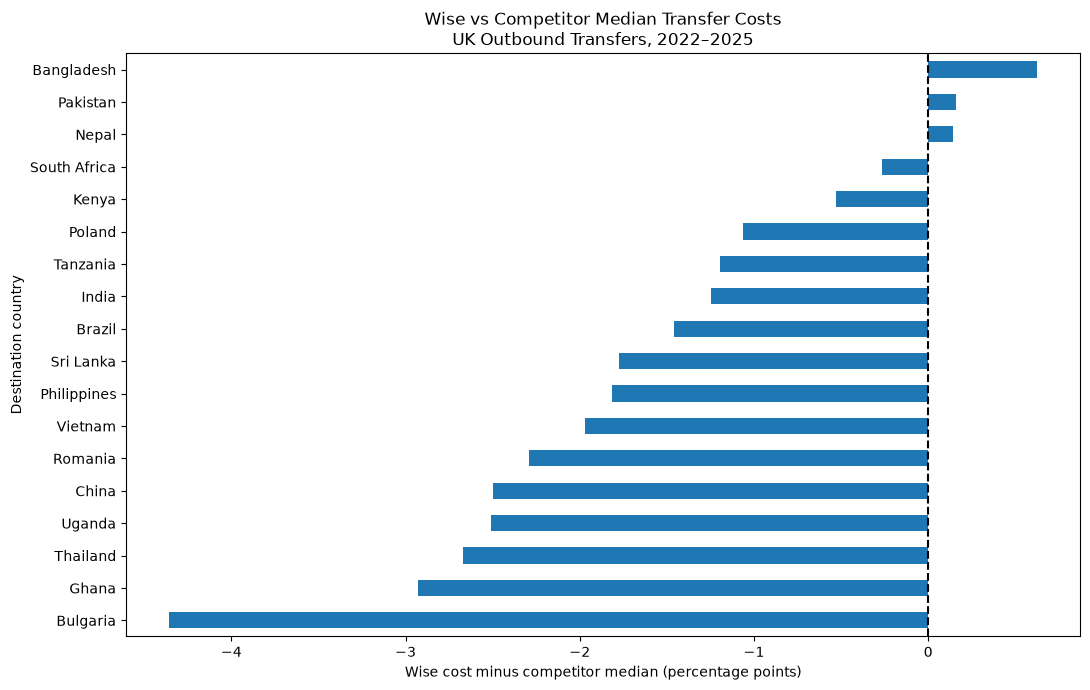

In [21]:
import matplotlib.pyplot as plt

# Aggregate Wise's cost differences by destination
corridor_comparison = (
    wise_comparison
    .groupby("destination_name")
    .agg(
        median_difference_pp=("cost_difference_pp", "median"),
        observations=("cost_difference_pp", "size")
    )
    .query("observations >= 10")
    .sort_values("median_difference_pp")
)

# Plot
plt.figure(figsize=(11, 7))

corridor_comparison["median_difference_pp"].plot(
    kind="barh"
)

plt.axvline(0, color="black", linestyle="--")

plt.xlabel("Wise cost minus competitor median (percentage points)")
plt.ylabel("Destination country")
plt.title(
    "Wise vs Competitor Median Transfer Costs\n"
    "UK Outbound Transfers, 2022–2025"
)

plt.tight_layout()
plt.show()

In [22]:
# Focus on corridors where Wise appears more expensive
focus_countries = ["Bangladesh", "Pakistan", "Nepal"]

focus_df = wise_comparison[
    wise_comparison["destination_name"].isin(focus_countries)
].copy()

# Summarise Wise's pricing differences
corridor_summary = (
    focus_df.groupby("destination_name")
    .agg(
        observations=("cost_difference_pp", "size"),
        wise_median_cost=("cc1 total cost %", "median"),
        competitor_median_cost=("competitor_median_cost", "median"),
        median_difference_pp=("cost_difference_pp", "median")
    )
    .round(3)
)

display(corridor_summary)

,observations,wise_median_cost,competitor_median_cost,median_difference_pp
destination_name,,,,
Bangladesh,36,7.615,4.805,0.623
Nepal,36,2.790,2.370,0.140
Pakistan,36,1.665,1.415,0.160


In [23]:
# Examine competitor pricing in the three corridors
competitor_focus = analysis_df[
    (analysis_df["destination_name"].isin(focus_countries)) &
    (analysis_df["provider"] != "Wise")
].copy()

competitor_summary = (
    competitor_focus.groupby(
        ["destination_name", "provider"]
    )
    .agg(
        observations=("cc1 total cost %", "size"),
        median_cost=("cc1 total cost %", "median")
    )
    .reset_index()
)

# Keep providers with at least 5 observations
competitor_summary = competitor_summary[
    competitor_summary["observations"] >= 5
]

# Display the lowest-cost providers per corridor
lowest_cost_providers = (
    competitor_summary
    .sort_values(
        ["destination_name", "median_cost"]
    )
    .groupby("destination_name")
    .head(5)
)

display(lowest_cost_providers)

,destination_name,provider,observations,median_cost
1,Bangladesh,IFIC Money Transfer,25,2.870
6,Bangladesh,Sendwave,26,3.955
2,Bangladesh,Lyca Remit,13,4.640
5,Bangladesh,Ria,23,4.990
7,Bangladesh,Small World,53,5.190
15,Nepal,Remitly,85,1.660
17,Nepal,Ria,24,2.015
14,Nepal,Orbit Remit,7,2.320
19,Nepal,WorldRemit,27,2.780
16,Nepal,Rewire,16,5.020


In [24]:
# Compare payment methods in the focus corridors
payment_comparison = analysis_df[
    analysis_df["destination_name"].isin(focus_countries)
].copy()

payment_comparison["provider_group"] = np.where(
    payment_comparison["provider"] == "Wise",
    "Wise",
    "Other providers"
)

payment_summary = (
    payment_comparison.groupby(
        ["destination_name", "provider_group",
         "payment instrument", "pickup method"],
        dropna=False
    )
    .size()
    .reset_index(name="observations")
    .sort_values(
        ["destination_name", "provider_group", "observations"],
        ascending=[True, True, False]
    )
)

display(payment_summary.head(40))

,destination_name,provider_group,payment instrument,pickup method,observations
18,Bangladesh,Other providers,Debit card,Cash,59
19,Bangladesh,Other providers,Debit card,Mobile wallet,45
17,Bangladesh,Other providers,Debit card,Bank account,43
9,Bangladesh,Other providers,Credit Card,Cash,42
10,Bangladesh,Other providers,Credit Card,Mobile wallet,38
1,Bangladesh,Other providers,Bank account transfer,Cash,34
8,Bangladesh,Other providers,Credit Card,Bank account,27
2,Bangladesh,Other providers,Bank account transfer,Mobile wallet,24
0,Bangladesh,Other providers,Bank account transfer,Bank account,22
12,Bangladesh,Other providers,"Credit Card,Debit card",Cash,9


In [25]:
import pandas as pd
import numpy as np

focus_countries = ["Bangladesh", "Pakistan", "Nepal"]

matched_df = analysis_df[
    analysis_df["destination_name"].isin(focus_countries)
].copy()

# Standardise payment instrument labels
matched_df["payment_method"] = (
    matched_df["payment instrument"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Standardise payout method labels
matched_df["payout_method"] = (
    matched_df["pickup method"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Keep only clearly defined single funding methods
valid_payment_methods = [
    "bank account transfer",
    "debit card",
    "credit card",
    "cash"
]

matched_df = matched_df[
    matched_df["payment_method"].isin(valid_payment_methods)
    & matched_df["payout_method"].notna()
].copy()

print("Total eligible observations:", len(matched_df))

print("\nWise observations:")
print((matched_df["provider"] == "Wise").sum())

print("\nCompetitor observations:")
print((matched_df["provider"] != "Wise").sum())

Total eligible observations: 931

Wise observations:
99

Competitor observations:
832


In [26]:
# Define matching variables
match_columns = [
    "destination_name",
    "period",
    "payment_method",
    "payout_method"
]

# Calculate competitor median within each matching group
competitor_benchmark = (
    matched_df[matched_df["provider"] != "Wise"]
    .groupby(match_columns)
    .agg(
        competitor_median_cost=("cc1 total cost %", "median"),
        competitor_count=("cc1 total cost %", "size"),
        competitor_providers=("provider", "nunique")
    )
    .reset_index()
)

# Extract Wise observations
wise_matched = matched_df[
    matched_df["provider"] == "Wise"
].copy()

# Join Wise observations to comparable competitor groups
wise_matched = wise_matched.merge(
    competitor_benchmark,
    on=match_columns,
    how="inner",
    validate="many_to_one"
)

# Calculate Wise's cost difference
wise_matched["cost_difference_pp"] = (
    wise_matched["cc1 total cost %"]
    - wise_matched["competitor_median_cost"]
)

print("Matched Wise observations:", len(wise_matched))

print("\nUnique matched groups:")
print(wise_matched[match_columns].drop_duplicates().shape[0])

print("\nMedian competitor count per matched observation:")
print(wise_matched["competitor_count"].median())

print("\nMedian cost difference:")
print(wise_matched["cost_difference_pp"].median())

print("\nPercentage of Wise observations below competitor median:")
print(
    round(
        (wise_matched["cost_difference_pp"] < 0).mean() * 100,
        2
    )
)

Matched Wise observations: 98

Unique matched groups:
98

Median competitor count per matched observation:
2.0

Median cost difference:
0.6799999999999999

Percentage of Wise observations below competitor median:
24.49


In [27]:
# Summarise strict matched comparisons
strict_summary = (
    wise_matched.groupby("destination_name")
    .agg(
        matched_observations=("cost_difference_pp", "size"),
        wise_median_cost=("cc1 total cost %", "median"),
        competitor_median_cost=("competitor_median_cost", "median"),
        median_difference_pp=("cost_difference_pp", "median"),
        mean_difference_pp=("cost_difference_pp", "mean"),
        competitor_count_median=("competitor_count", "median")
    )
)

# Percentage of observations where Wise is cheaper
cheaper_percentage = (
    wise_matched.groupby("destination_name")["cost_difference_pp"]
    .apply(lambda x: (x < 0).mean() * 100)
)

strict_summary["wise_cheaper_pct"] = cheaper_percentage

display(strict_summary.round(3))

,matched_observations,wise_median_cost,competitor_median_cost,median_difference_pp,mean_difference_pp,competitor_count_median,wise_cheaper_pct
destination_name,,,,,,,
Bangladesh,32,7.825,6.065,1.415,2.225,3.0,18.750
Nepal,33,2.820,2.025,0.365,0.559,2.0,18.182
Pakistan,33,1.650,0.815,0.770,0.705,2.0,36.364


In [28]:
# Assess the reliability of our matched sample
sample_quality = (
    wise_matched.groupby("destination_name")
    .agg(
        matched_observations=("cost_difference_pp", "size"),
        unique_quarters=("period", "nunique"),
        unique_payment_methods=("payment_method", "nunique"),
        median_competitors=("competitor_count", "median"),
        minimum_competitors=("competitor_count", "min")
    )
)

display(sample_quality)

,matched_observations,unique_quarters,unique_payment_methods,median_competitors,minimum_competitors
destination_name,,,,,
Bangladesh,32,12,3,3.0,1
Nepal,33,13,3,2.0,1
Pakistan,33,13,3,2.0,1


In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Calculate median pricing differences by quarter and destination
quarterly_summary = (
    wise_matched
    .groupby(["period", "destination_name"])
    .agg(
        median_difference_pp=("cost_difference_pp", "median"),
        observations=("cost_difference_pp", "size")
    )
    .reset_index()
)

# Convert period into chronological order
quarterly_summary["year"] = (
    quarterly_summary["period"].str[:4].astype(int)
)

quarterly_summary["quarter"] = (
    quarterly_summary["period"]
    .str.extract(r"_(\d)Q")[0]
    .astype(int)
)

quarterly_summary = quarterly_summary.sort_values(
    ["year", "quarter"]
)

display(quarterly_summary.head(15))

,period,destination_name,median_difference_pp,observations,year,quarter
0,2022_1Q,Nepal,0.445,1,2022,1
1,2022_1Q,Pakistan,-0.180,1,2022,1
2,2022_2Q,Bangladesh,-0.600,1,2022,2
3,2022_2Q,Nepal,0.740,1,2022,2
4,2022_2Q,Pakistan,0.710,1,2022,2
5,2022_3Q,Bangladesh,9.220,1,2022,3
6,2022_3Q,Nepal,0.485,1,2022,3
7,2022_3Q,Pakistan,1.260,1,2022,3
8,2022_4Q,Bangladesh,7.415,3,2022,4
9,2022_4Q,Nepal,-0.475,3,2022,4


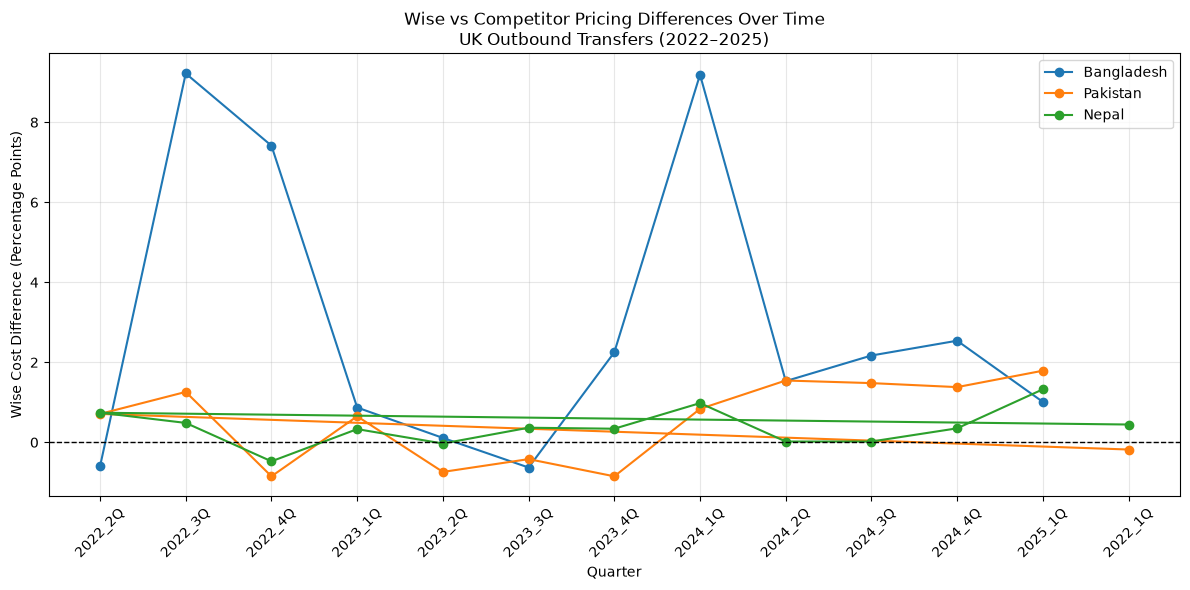

In [30]:
plt.figure(figsize=(12, 6))

for country in ["Bangladesh", "Pakistan", "Nepal"]:

    country_data = quarterly_summary[
        quarterly_summary["destination_name"] == country
    ]

    plt.plot(
        country_data["period"],
        country_data["median_difference_pp"],
        marker="o",
        label=country
    )

plt.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.title(
    "Wise vs Competitor Pricing Differences Over Time\n"
    "UK Outbound Transfers (2022–2025)"
)

plt.xlabel("Quarter")
plt.ylabel("Wise Cost Difference (Percentage Points)")
plt.legend()
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [31]:
payment_method_summary = (
    wise_matched
    .groupby(["destination_name", "payment_method"])
    .agg(
        observations=("cost_difference_pp", "size"),
        median_difference_pp=("cost_difference_pp", "median"),
        mean_difference_pp=("cost_difference_pp", "mean")
    )
    .reset_index()
)

display(
    payment_method_summary.sort_values(
        ["destination_name", "payment_method"]
    ).round(3)
)

,destination_name,payment_method,observations,median_difference_pp,mean_difference_pp
0,Bangladesh,bank account transfer,12,0.203,1.438
1,Bangladesh,credit card,10,2.115,2.249
2,Bangladesh,debit card,10,1.892,3.145
3,Nepal,bank account transfer,13,0.330,0.296
4,Nepal,credit card,10,1.860,1.455
5,Nepal,debit card,10,0.180,0.005
6,Pakistan,bank account transfer,13,0.470,0.230
7,Pakistan,credit card,10,2.072,1.475
8,Pakistan,debit card,10,0.742,0.555


In [32]:
robustness_results = []

for min_competitors in [1, 2, 3, 5]:

    subset = wise_matched[
        wise_matched["competitor_count"] >= min_competitors
    ]

    for country, group in subset.groupby("destination_name"):

        robustness_results.append({
            "destination": country,
            "min_competitors": min_competitors,
            "observations": len(group),
            "median_difference_pp": group[
                "cost_difference_pp"
            ].median(),
            "wise_cheaper_pct": (
                group["cost_difference_pp"] < 0
            ).mean() * 100
        })

robustness_df = pd.DataFrame(robustness_results)

display(
    robustness_df.sort_values(
        ["destination", "min_competitors"]
    ).round(3)
)

,destination,min_competitors,observations,median_difference_pp,wise_cheaper_pct
0,Bangladesh,1,32,1.415,18.750
3,Bangladesh,2,30,1.415,16.667
6,Bangladesh,3,17,1.980,11.765
9,Bangladesh,5,1,9.180,0.000
1,Nepal,1,33,0.365,18.182
4,Nepal,2,29,0.365,20.690
7,Nepal,3,4,0.270,25.000
2,Pakistan,1,33,0.770,36.364
5,Pakistan,2,27,0.470,44.444
8,Pakistan,3,14,-0.015,50.000


In [33]:
rng = np.random.default_rng(42)

bootstrap_results = []

for country, group in wise_matched.groupby("destination_name"):

    quarters = group["period"].unique()

    if len(quarters) < 2:
        continue

    bootstrap_medians = []

    for _ in range(2000):

        sampled_quarters = rng.choice(
            quarters,
            size=len(quarters),
            replace=True
        )

        sampled_values = np.concatenate([
            group.loc[
                group["period"] == quarter,
                "cost_difference_pp"
            ].to_numpy()
            for quarter in sampled_quarters
        ])

        bootstrap_medians.append(
            np.median(sampled_values)
        )

    lower, upper = np.percentile(
        bootstrap_medians,
        [2.5, 97.5]
    )

    bootstrap_results.append({
        "destination": country,
        "median_difference_pp": group[
            "cost_difference_pp"
        ].median(),
        "ci_lower": lower,
        "ci_upper": upper,
        "quarters": len(quarters),
        "observations": len(group)
    })

bootstrap_df = pd.DataFrame(bootstrap_results)

display(bootstrap_df.round(3))

,destination,median_difference_pp,ci_lower,ci_upper,quarters,observations
0,Bangladesh,1.415,0.282,2.59,12,32
1,Nepal,0.365,0.210,0.87,13,33
2,Pakistan,0.770,-0.470,1.38,13,33


In [34]:
# Focus on Bangladesh
bangladesh_df = wise_matched[
    wise_matched["destination_name"] == "Bangladesh"
].copy()

# Sort by the largest positive pricing differences
bangladesh_spikes = (
    bangladesh_df.sort_values(
        "cost_difference_pp",
        ascending=False
    )
)

columns_to_display = [
    "period",
    "provider",
    "payment_method",
    "payout_method",
    "cc1 lcu fee",
    "cc1 fx margin",
    "cc1 total cost %",
    "competitor_median_cost",
    "competitor_count",
    "competitor_providers",
    "cost_difference_pp"
]

display(
    bangladesh_spikes[columns_to_display]
    .head(15)
    .round(3)
)

,period,provider,payment_method,payout_method,cc1 lcu fee,cc1 fx margin,cc1 total cost %,competitor_median_cost,competitor_count,competitor_providers,cost_difference_pp
55,2024_1Q,Wise,debit card,bank account,2.54,8.85,10.97,1.725,4,4,9.245
7,2022_3Q,Wise,bank account transfer,bank account,2.04,14.82,16.52,7.300,1,1,9.220
54,2024_1Q,Wise,credit card,bank account,2.54,8.85,10.97,1.780,3,3,9.190
9,2022_4Q,Wise,debit card,bank account,2.40,14.40,16.40,7.220,5,5,9.180
8,2022_4Q,Wise,bank account transfer,bank account,2.04,14.40,16.10,8.685,2,2,7.415
53,2024_1Q,Wise,bank account transfer,bank account,2.04,8.85,10.55,6.625,2,2,3.925
46,2023_4Q,Wise,debit card,bank account,2.54,9.11,11.23,7.720,4,4,3.510
63,2024_2Q,Wise,credit card,bank account,6.78,7.48,13.13,10.030,3,3,3.100
81,2024_4Q,Wise,credit card,bank account,6.56,2.15,7.62,4.905,2,2,2.715
75,2024_3Q,Wise,credit card,bank account,6.56,3.67,9.14,6.550,2,2,2.590


In [35]:
# Identify the five largest Wise pricing differences
top_spikes = bangladesh_spikes.head(5)

# Match the underlying competitor observations
competitor_details = analysis_df[
    (analysis_df["destination_name"] == "Bangladesh") &
    (analysis_df["provider"] != "Wise")
].copy()

# Standardise methods consistently with Step 5
competitor_details["payment_method"] = (
    competitor_details["payment instrument"]
    .astype("string")
    .str.strip()
    .str.lower()
)

competitor_details["payout_method"] = (
    competitor_details["pickup method"]
    .astype("string")
    .str.strip()
    .str.lower()
)

match_columns = [
    "destination_name",
    "period",
    "payment_method",
    "payout_method"
]

# Restrict competitors to the exact matching groups
spike_competitors = competitor_details.merge(
    top_spikes[match_columns].drop_duplicates(),
    on=match_columns,
    how="inner"
)

display(
    spike_competitors[
        [
            "period",
            "provider",
            "payment_method",
            "payout_method",
            "cc1 lcu fee",
            "cc1 fx margin",
            "cc1 total cost %"
        ]
    ].sort_values(
        ["period", "cc1 total cost %"]
    ).round(3)
)

,period,provider,payment_method,payout_method,cc1 lcu fee,cc1 fx margin,cc1 total cost %
0,2022_3Q,Remitly,bank account transfer,bank account,0.00,7.30,7.30
5,2022_4Q,Small World,debit card,bank account,1.99,3.54,5.19
2,2022_4Q,IFIC Money Transfer,debit card,bank account,4.50,3.16,6.91
6,2022_4Q,WorldRemit,bank account transfer,bank account,0.00,7.22,7.22
7,2022_4Q,WorldRemit,debit card,bank account,0.00,7.22,7.22
1,2022_4Q,Lyca Remit,debit card,bank account,2.50,7.43,9.52
3,2022_4Q,Remitly,bank account transfer,bank account,0.00,10.15,10.15
4,2022_4Q,Remitly,debit card,bank account,0.00,10.15,10.15
8,2024_1Q,Small World,credit card,bank account,1.99,-0.23,1.43
9,2024_1Q,Small World,debit card,bank account,1.99,-0.23,1.43


In [36]:
# Calculate Wise's transfer fee as a percentage
bangladesh_df["fee_percentage"] = (
    bangladesh_df["cc1 lcu fee"]
    / bangladesh_df["cc1 lcu amount"]
) * 100

# Examine the relationship between fee and total cost
fee_analysis = bangladesh_df[
    [
        "period",
        "payment_method",
        "cc1 lcu fee",
        "fee_percentage",
        "cc1 fx margin",
        "cc1 total cost %",
        "cost_difference_pp"
    ]
].copy()

display(
    fee_analysis.sort_values(
        "cost_difference_pp",
        ascending=False
    ).head(15).round(3)
)

,period,payment_method,cc1 lcu fee,fee_percentage,cc1 fx margin,cc1 total cost %,cost_difference_pp
55,2024_1Q,debit card,2.54,2.117,8.85,10.97,9.245
7,2022_3Q,bank account transfer,2.04,1.700,14.82,16.52,9.220
54,2024_1Q,credit card,2.54,2.117,8.85,10.97,9.190
9,2022_4Q,debit card,2.40,2.000,14.40,16.40,9.180
8,2022_4Q,bank account transfer,2.04,1.700,14.40,16.10,7.415
53,2024_1Q,bank account transfer,2.04,1.700,8.85,10.55,3.925
46,2023_4Q,debit card,2.54,2.117,9.11,11.23,3.510
63,2024_2Q,credit card,6.78,5.650,7.48,13.13,3.100
81,2024_4Q,credit card,6.56,5.467,2.15,7.62,2.715
75,2024_3Q,credit card,6.56,5.467,3.67,9.14,2.590


In [37]:
# Focus on quarters with unusually high Bangladesh FX margins
focus_periods = ["2022_3Q", "2022_4Q", "2024_1Q"]

wise_fx = analysis_df[
    (analysis_df["provider"] == "Wise") &
    (analysis_df["period"].isin(focus_periods))
].copy()

# Calculate median FX margin by destination and quarter
fx_country_summary = (
    wise_fx.groupby(["period", "destination_name"])
    .agg(
        observations=("cc1 fx margin", "size"),
        median_fx_margin=("cc1 fx margin", "median"),
        median_total_cost=("cc1 total cost %", "median")
    )
    .reset_index()
)

display(
    fx_country_summary.sort_values(
        ["period", "median_fx_margin"],
        ascending=[True, False]
    ).round(3)
)

,period,destination_name,observations,median_fx_margin,median_total_cost
0,2022_3Q,Bangladesh,2,14.820,16.670
9,2022_3Q,Pakistan,2,1.000,2.140
1,2022_3Q,Brazil,1,0.720,3.530
11,2022_3Q,Poland,2,0.015,1.015
13,2022_3Q,South Africa,2,0.005,4.205
3,2022_3Q,China,2,0.000,1.490
4,2022_3Q,Ghana,2,0.000,1.740
6,2022_3Q,Kenya,2,0.000,1.720
10,2022_3Q,Philippines,2,0.000,1.210
12,2022_3Q,Romania,2,0.000,1.015


In [38]:
# Select Bangladesh observations in the relevant quarters
bd_fx = analysis_df[
    (analysis_df["destination_name"] == "Bangladesh") &
    (analysis_df["period"].isin(focus_periods))
].copy()

bd_fx["provider_group"] = np.where(
    bd_fx["provider"] == "Wise",
    "Wise",
    "Other providers"
)

fx_comparison = (
    bd_fx.groupby(["period", "provider_group"])
    .agg(
        observations=("cc1 fx margin", "size"),
        median_fx_margin=("cc1 fx margin", "median"),
        median_total_cost=("cc1 total cost %", "median")
    )
    .reset_index()
)

display(fx_comparison.round(3))

,period,provider_group,observations,median_fx_margin,median_total_cost
0,2022_3Q,Other providers,18,3.615,5.285
1,2022_3Q,Wise,2,14.820,16.670
2,2022_4Q,Other providers,38,7.220,8.555
3,2022_4Q,Wise,3,14.400,16.100
4,2024_1Q,Other providers,33,1.780,4.270
5,2024_1Q,Wise,3,8.850,10.970


In [39]:
# Start with our strictly matched Bangladesh observations
bd_sensitivity = wise_matched[
    wise_matched["destination_name"] == "Bangladesh"
].copy()

sensitivity_results = []

# None means no FX-margin restriction
for threshold in [None, 15, 10, 5]:

    if threshold is None:
        subset = bd_sensitivity.copy()
        label = "All observations"
    else:
        subset = bd_sensitivity[
            bd_sensitivity["cc1 fx margin"] <= threshold
        ].copy()
        label = f"Wise FX margin <= {threshold}%"

    sensitivity_results.append({
        "scenario": label,
        "observations": len(subset),
        "median_difference_pp": (
            subset["cost_difference_pp"].median()
            if len(subset) else np.nan
        ),
        "mean_difference_pp": (
            subset["cost_difference_pp"].mean()
            if len(subset) else np.nan
        ),
        "wise_cheaper_pct": (
            (subset["cost_difference_pp"] < 0).mean() * 100
            if len(subset) else np.nan
        )
    })

sensitivity_df = pd.DataFrame(sensitivity_results)

display(sensitivity_df.round(3))

,scenario,observations,median_difference_pp,mean_difference_pp,wise_cheaper_pct
0,All observations,32,1.415,2.225,18.75
1,Wise FX margin <= 15%,32,1.415,2.225,18.75
2,Wise FX margin <= 10%,29,1.010,1.565,20.69
3,Wise FX margin <= 5%,16,0.697,0.897,18.75


In [40]:
# Inspect the original observations with high Wise FX margins
high_fx_notes = analysis_df[
    (analysis_df["provider"] == "Wise") &
    (analysis_df["destination_name"] == "Bangladesh") &
    (analysis_df["cc1 fx margin"] > 5)
].copy()

columns = [
    "period",
    "cc1 fx margin",
    "cc1 total cost %",
    "transparent",
    "Standard Note",
    "note2",
    "date"
]

display(
    high_fx_notes[columns]
    .sort_values("period")
)

,period,cc1 fx margin,cc1 total cost %,transparent,Standard Note,note2,date
124280,2022_3Q,14.82,16.52,yes,Alternative interbank rates sourced from unb.c...,NaN,30/Aug/2022
124281,2022_3Q,14.82,16.82,yes,Alternative interbank rates sourced from unb.c...,NaN,30/Aug/2022
125503,2022_4Q,14.40,16.10,yes,Alternative interbank rates sourced from BD ne...,NaN,02/Nov/2022
125504,2022_4Q,14.40,16.40,yes,Alternative interbank rates sourced from BD ne...,NaN,02/Nov/2022
132709,2022_4Q,7.20,9.20,yes,Alternative interbank rates sourced from BD ne...,NaN,06/Dec/2022
152397,2023_3Q,5.91,7.61,yes,NaN,NaN,04/Sep/2023
152398,2023_3Q,5.91,8.03,yes,NaN,NaN,04/Sep/2023
152399,2023_3Q,5.91,8.03,yes,NaN,NaN,04/Sep/2023
159140,2023_4Q,9.11,10.81,yes,Alternative interbank rates sourced from the D...,NaN,28/Nov/2023
159141,2023_4Q,9.11,11.23,yes,Alternative interbank rates sourced from the D...,NaN,28/Nov/2023


In [41]:
# Display complete explanatory notes for Wise's
# high-FX-margin Bangladesh observations

pd.set_option("display.max_colwidth", None)

notes_summary = (
    high_fx_notes[
        ["period", "date", "cc1 fx margin",
         "Standard Note", "note2"]
    ]
    .drop_duplicates()
    .sort_values(["period", "date"])
)

for _, row in notes_summary.iterrows():

    print("=" * 75)
    print("Period:", row["period"])
    print("Date:", row["date"])
    print("FX margin:", row["cc1 fx margin"])

    print("\nStandard Note:")
    print(row["Standard Note"])

    print("\nAdditional Note:")
    print(row["note2"])

    print()

Period: 2022_3Q
Date: 30/Aug/2022
FX margin: 14.82

Standard Note:
Alternative interbank rates sourced from unb.com.bd and orthosongbad.com.

Additional Note:
nan

Period: 2022_4Q
Date: 02/Nov/2022
FX margin: 14.4

Standard Note:
Alternative interbank rates sourced from BD news. The prices also are affected by the 2.5 % subsidy the government provides for all foreign currency denominated incoming transfers. Calculated based on USD/BDT rate.

Additional Note:
nan

Period: 2022_4Q
Date: 06/Dec/2022
FX margin: 7.2

Standard Note:
Alternative interbank rates sourced from BD news. The prices also are affected by the 2.5 % subsidy the government provides for all foreign currency denominated incoming transfers. Calculated based on USD/BDT rate.

Additional Note:
nan

Period: 2023_3Q
Date: 04/Sep/2023
FX margin: 5.91

Standard Note:
nan

Additional Note:
nan

Period: 2023_4Q
Date: 28/Nov/2023
FX margin: 9.11

Standard Note:
Alternative interbank rates sourced from the Daily Star in Bangladesh.

In [42]:
# STEP 8: FX margin analysis by methodology note

import pandas as pd
import numpy as np

# All Wise observations for UK -> Bangladesh
bd_wise = analysis_df[
    (analysis_df["provider"] == "Wise") &
    (analysis_df["destination_name"] == "Bangladesh")
].copy()

# Identify observations referencing alternative exchange rates
bd_wise["alternative_rate_note"] = (
    bd_wise["Standard Note"]
    .fillna("")
    .str.contains(
        "alternative interbank rates",
        case=False,
        na=False
    )
)

# Identify observations mentioning government subsidies
bd_wise["subsidy_note"] = (
    bd_wise["Standard Note"]
    .fillna("")
    .str.contains(
        "subsidy",
        case=False,
        na=False
    )
)

# Summarise FX margins by note category
methodology_summary = (
    bd_wise.groupby(
        ["alternative_rate_note", "subsidy_note"]
    )
    .agg(
        observations=("cc1 fx margin", "size"),
        median_fx_margin=("cc1 fx margin", "median"),
        mean_fx_margin=("cc1 fx margin", "mean"),
        median_total_cost=("cc1 total cost %", "median")
    )
    .reset_index()
)

display(methodology_summary.round(3))

,alternative_rate_note,subsidy_note,observations,median_fx_margin,mean_fx_margin,median_total_cost
0,False,False,7,0.02,2.536,2.02
1,True,False,8,2.46,5.465,6.33
2,True,True,21,7.48,6.154,10.55


In [43]:
# Quarterly FX margins and methodology flags

quarterly_fx = (
    bd_wise.groupby("period")
    .agg(
        observations=("cc1 fx margin", "size"),
        median_fx_margin=("cc1 fx margin", "median"),
        median_total_cost=("cc1 total cost %", "median"),
        alternative_rate_observations=(
            "alternative_rate_note", "sum"
        ),
        subsidy_note_observations=(
            "subsidy_note", "sum"
        )
    )
    .reset_index()
)

display(quarterly_fx.round(3))

,period,observations,median_fx_margin,median_total_cost,alternative_rate_observations,subsidy_note_observations
0,2022_1Q,2,0.00,1.800,0,0
1,2022_2Q,2,0.01,1.865,0,0
2,2022_3Q,2,14.82,16.670,2,0
3,2022_4Q,3,14.40,16.100,3,3
4,2023_1Q,3,2.58,4.580,3,3
5,2023_2Q,3,-0.21,1.490,3,3
6,2023_3Q,3,5.91,8.030,0,0
7,2023_4Q,3,9.11,11.230,3,3
8,2024_1Q,3,8.85,10.970,3,3
9,2024_2Q,3,7.48,11.280,3,3


In [54]:
import pandas as pd
import numpy as np

# STEP 9: Pricing Anomaly Detection

# Start with the original matched dataset
anomaly_df = wise_matched.copy()

# Pricing difference in percentage points
anomaly_df["pricing_gap_pp"] = anomaly_df["cost_difference_pp"]

# Calculate robust Z-scores using median absolute deviation
def robust_z_score(series):

    median = series.median()

    mad = np.median(np.abs(series - median))

    if mad == 0 or pd.isna(mad):
        return pd.Series(0.0, index=series.index)

    return 0.6745 * (series - median) / mad


# Detect anomalies separately for each destination
anomaly_df["robust_z_score"] = (
    anomaly_df.groupby("destination_name")["pricing_gap_pp"]
    .transform(robust_z_score)
)

# Flag unusually large pricing differences
anomaly_df["pricing_anomaly"] = (
    anomaly_df["robust_z_score"].abs() > 3.5
)

# Summarise anomalies by destination
anomaly_summary = (
    anomaly_df.groupby("destination_name")
    .agg(
        observations=("pricing_gap_pp", "size"),
        anomalies=("pricing_anomaly", "sum"),
        median_pricing_gap_pp=("pricing_gap_pp", "median"),
        maximum_pricing_gap_pp=("pricing_gap_pp", "max"),
        minimum_pricing_gap_pp=("pricing_gap_pp", "min")
    )
    .reset_index()
)

anomaly_summary["anomaly_percentage"] = (
    anomaly_summary["anomalies"]
    / anomaly_summary["observations"]
    * 100
)

print("PRICING ANOMALY SUMMARY")
display(anomaly_summary.round(3))

print("\nFLAGGED PRICING ANOMALIES")

flagged_anomalies = anomaly_df[
    anomaly_df["pricing_anomaly"]
].sort_values(
    "pricing_gap_pp",
    ascending=False
)

display(
    flagged_anomalies[
        [
            "period",
            "destination_name",
            "payment_method",
            "cc1 total cost %",
            "competitor_median_cost",
            "pricing_gap_pp",
            "robust_z_score"
        ]
    ].round(3)
)

print("\nTotal observations:", len(anomaly_df))
print("Total anomalies:", anomaly_df["pricing_anomaly"].sum())

PRICING ANOMALY SUMMARY


,destination_name,observations,anomalies,median_pricing_gap_pp,maximum_pricing_gap_pp,minimum_pricing_gap_pp,anomaly_percentage
0,Bangladesh,32,4,1.415,9.245,-2.175,12.500
1,Nepal,33,3,0.365,2.875,-2.560,9.091
2,Pakistan,33,0,0.770,3.350,-1.515,0.000



FLAGGED PRICING ANOMALIES


,period,destination_name,payment_method,cc1 total cost %,competitor_median_cost,pricing_gap_pp,robust_z_score
55,2024_1Q,Bangladesh,debit card,10.97,1.725,9.245,4.055
7,2022_3Q,Bangladesh,bank account transfer,16.52,7.300,9.220,4.042
54,2024_1Q,Bangladesh,credit card,10.97,1.780,9.190,4.026
9,2022_4Q,Bangladesh,debit card,16.40,7.220,9.180,4.021
93,2025_1Q,Nepal,credit card,4.46,1.585,2.875,4.286
20,2023_1Q,Nepal,credit card,5.70,3.225,2.475,3.603
15,2022_4Q,Nepal,debit card,2.82,5.380,-2.560,-4.995



Total observations: 98
Total anomalies: 7


In [55]:
# STEP 10: Sensitivity Analysis
# Evaluate whether pricing anomalies influence our conclusions

import pandas as pd
import numpy as np

# Create analysis scenarios
scenarios = {
    "All observations": anomaly_df.copy(),

    "Excluding anomalies": anomaly_df[
        ~anomaly_df["pricing_anomaly"]
    ].copy(),

    "Excluding anomalies (2+ competitors)": anomaly_df[
        (~anomaly_df["pricing_anomaly"]) &
        (anomaly_df["competitor_count"] >= 2)
    ].copy()
}

results = []

for scenario_name, scenario_data in scenarios.items():

    for destination, group in scenario_data.groupby("destination_name"):

        results.append({
            "scenario": scenario_name,
            "destination": destination,
            "observations": len(group),
            "median_gap_pp": group["pricing_gap_pp"].median(),
            "mean_gap_pp": group["pricing_gap_pp"].mean(),
            "wise_cheaper_pct": (
                group["pricing_gap_pp"] < 0
            ).mean() * 100
        })

sensitivity_summary = pd.DataFrame(results)

print("SENSITIVITY ANALYSIS RESULTS")

display(
    sensitivity_summary.round(3)
)

SENSITIVITY ANALYSIS RESULTS


,scenario,destination,observations,median_gap_pp,mean_gap_pp,wise_cheaper_pct
0,All observations,Bangladesh,32,1.415,2.225,18.750
1,All observations,Nepal,33,0.365,0.559,18.182
2,All observations,Pakistan,33,0.770,0.705,36.364
3,Excluding anomalies,Bangladesh,28,0.940,1.227,21.429
4,Excluding anomalies,Nepal,30,0.358,0.522,16.667
5,Excluding anomalies,Pakistan,33,0.770,0.705,36.364
6,Excluding anomalies (2+ competitors),Bangladesh,27,1.010,1.295,18.519
7,Excluding anomalies (2+ competitors),Nepal,26,0.358,0.532,19.231
8,Excluding anomalies (2+ competitors),Pakistan,27,0.470,0.323,44.444


In [56]:
# STEP 11: PRICING OPPORTUNITY PRIORITISATION

import pandas as pd
import numpy as np

# Use the matched observations from our previous analysis
priority_df = anomaly_df.copy()

# Ensure destination_name is available
if "destination_name" not in priority_df.columns:
    if "destination_name" in priority_df.index.names:
        priority_df = priority_df.reset_index()
    else:
        raise KeyError(
            "destination_name is missing. "
            "Check the dataframe used to construct anomaly_df."
        )

# Ensure pricing_anomaly is boolean
priority_df["pricing_anomaly"] = (
    priority_df["pricing_anomaly"].fillna(False).astype(bool)
)

# Create summary metrics
priority_summary = (
    priority_df.groupby("destination_name")
    .agg(
        observations=("pricing_gap_pp", "size"),
        median_gap_pp=("pricing_gap_pp", "median"),
        wise_cheaper_pct=(
            "pricing_gap_pp",
            lambda x: (x < 0).mean() * 100
        ),
        median_competitors=("competitor_count", "median"),
        anomalies=("pricing_anomaly", "sum")
    )
    .reset_index()
)

# Calculate median gap after removing anomalies
clean_df = priority_df[
    ~priority_df["pricing_anomaly"]
].copy()

clean_summary = (
    clean_df.groupby("destination_name")["pricing_gap_pp"]
    .median()
    .rename("clean_median_gap_pp")
    .reset_index()
)

priority_summary = priority_summary.merge(
    clean_summary,
    on="destination_name",
    how="left"
)

# SCORING FRAMEWORK
# Each criterion receives 0, 1 or 2 points.

# 1. Pricing gap
priority_summary["gap_score"] = np.select(
    [
        priority_summary["median_gap_pp"] >= 1.0,
        priority_summary["median_gap_pp"] >= 0.5
    ],
    [2, 1],
    default=0
)

# 2. Consistency
priority_summary["wise_more_expensive_pct"] = (
    100 - priority_summary["wise_cheaper_pct"]
)

priority_summary["consistency_score"] = np.select(
    [
        priority_summary["wise_more_expensive_pct"] >= 75,
        priority_summary["wise_more_expensive_pct"] >= 50
    ],
    [2, 1],
    default=0
)

# 3. Robustness
priority_summary["robustness_score"] = np.select(
    [
        priority_summary["clean_median_gap_pp"] >= 0.75,
        priority_summary["clean_median_gap_pp"] > 0
    ],
    [2, 1],
    default=0
)

# 4. Evidence quality
priority_summary["evidence_score"] = np.select(
    [
        (priority_summary["observations"] >= 30) &
        (priority_summary["median_competitors"] >= 3),

        (priority_summary["observations"] >= 20) &
        (priority_summary["median_competitors"] >= 2)
    ],
    [2, 1],
    default=0
)

# Total score: maximum 8
priority_summary["priority_score"] = (
    priority_summary["gap_score"] +
    priority_summary["consistency_score"] +
    priority_summary["robustness_score"] +
    priority_summary["evidence_score"]
)

# Priority categories
priority_summary["priority_level"] = pd.cut(
    priority_summary["priority_score"],
    bins=[-1, 3, 5, 8],
    labels=["Low", "Medium", "High"]
)

# Flag known methodological concerns
priority_summary["methodology_review_required"] = (
    priority_summary["destination_name"].eq("Bangladesh")
)

# Sort by priority score
priority_summary = priority_summary.sort_values(
    "priority_score",
    ascending=False
)

print("WISE PRICING OPPORTUNITY PRIORITISATION")

display(
    priority_summary[
        [
            "destination_name",
            "observations",
            "median_gap_pp",
            "clean_median_gap_pp",
            "wise_more_expensive_pct",
            "median_competitors",
            "priority_score",
            "priority_level",
            "methodology_review_required"
        ]
    ].round(3)
)

WISE PRICING OPPORTUNITY PRIORITISATION


,destination_name,observations,median_gap_pp,clean_median_gap_pp,wise_more_expensive_pct,median_competitors,priority_score,priority_level,methodology_review_required
0,Bangladesh,32,1.415,0.940,81.250,3.0,8,High,True
2,Pakistan,33,0.770,0.770,63.636,2.0,5,Medium,False
1,Nepal,33,0.365,0.358,81.818,2.0,4,Medium,False


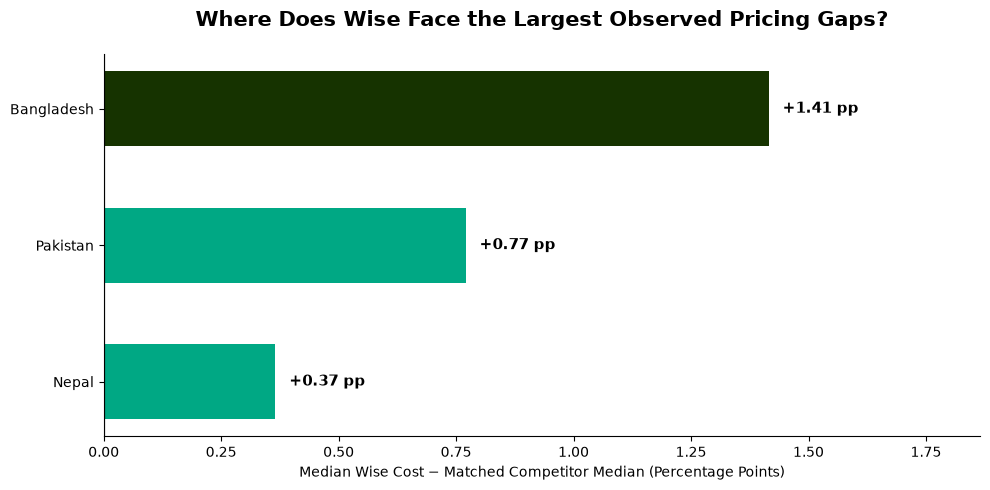

In [62]:
import matplotlib.pyplot as plt
import numpy as np

# Sort destinations by median pricing gap
plot_df = priority_summary.sort_values(
    "median_gap_pp",
    ascending=True
)

fig, ax = plt.subplots(figsize=(10, 5))

colors = [
    "#00A884" if destination != "Bangladesh" else "#163300"
    for destination in plot_df["destination_name"]
]

bars = ax.barh(
    plot_df["destination_name"],
    plot_df["median_gap_pp"],
    color=colors,
    height=0.55
)

# Add values
for bar in bars:
    width = bar.get_width()

    ax.text(
        width + 0.03,
        bar.get_y() + bar.get_height() / 2,
        f"+{width:.2f} pp",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

ax.axvline(0, color="black", linewidth=0.8)

ax.set_title(
    "Where Does Wise Face the Largest Observed Pricing Gaps?",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlabel(
    "Median Wise Cost − Matched Competitor Median (Percentage Points)",
    fontsize=10
)

ax.set_xlim(
    0,
    plot_df["median_gap_pp"].max() + 0.45
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "../wise_pricing_gap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    "../outputs/figures/pricing_gaps_by_corridor.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

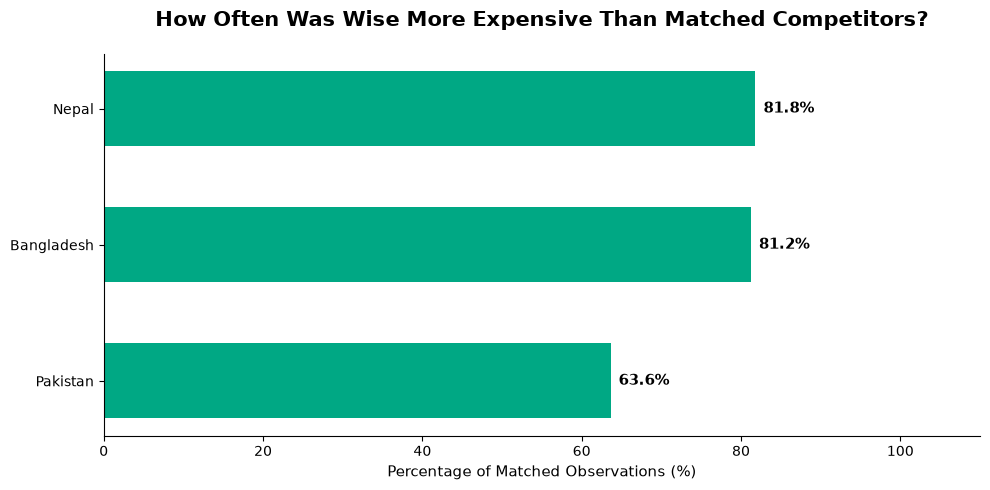

In [63]:
fig, ax = plt.subplots(figsize=(10, 5))

plot_df = priority_summary.sort_values(
    "wise_more_expensive_pct",
    ascending=True
)

bars = ax.barh(
    plot_df["destination_name"],
    plot_df["wise_more_expensive_pct"],
    color="#00A884",
    height=0.55
)

for bar in bars:
    width = bar.get_width()

    ax.text(
        width + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.1f}%",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

ax.set_xlim(0, 110)

ax.set_title(
    "How Often Was Wise More Expensive Than Matched Competitors?",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlabel(
    "Percentage of Matched Observations (%)",
    fontsize=11
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "../wise_competitor_frequency.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()